# 🔵 Logistic Regression from Scratch

Logistic Regression is a **classification algorithm** used to predict the probability that an input belongs to a particular class (e.g. spam vs. not spam, disease vs. no disease).

Even though it has "regression" in the name, it is used for **classification**, not predicting continuous values.

## 📖 What You'll Learn
1. The intuition and math behind Logistic Regression
2. The Sigmoid function
3. The Cost Function (Binary Cross-Entropy / Log Loss)
4. Gradient Descent for optimization
5. Implementing Logistic Regression **from scratch** using only NumPy
6. Comparing our implementation with scikit-learn's `LogisticRegression`
7. Evaluating the model with accuracy, confusion matrix, precision, recall, F1-score
8. Visualizing the decision boundary

## 📊 Dataset
We'll use the classic **[Breast Cancer Wisconsin dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-wisconsin-diagnostic-dataset)**, available directly through `sklearn.datasets`. It's a binary classification problem: predict whether a tumor is **malignant (0)** or **benign (1)**.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc

sns.set_style("whitegrid")
np.random.seed(42)

## 2. Load and Explore the Dataset

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

print("Shape of dataset:", X.shape)
print("Classes:", data.target_names)
df.head()

Shape of dataset: (569, 30)
Classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. The Math Behind Logistic Regression

### 3.1 The Sigmoid Function

Logistic Regression converts a linear combination of inputs into a probability between 0 and 1 using the **sigmoid function**:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

where:

$$
z = w^T x + b
$$

- $w$ = weights
- $b$ = bias
- $x$ = input features

### 3.2 Cost Function (Binary Cross-Entropy)

We can't use Mean Squared Error here because it makes the cost function non-convex for classification. Instead, we use **Log Loss**:

$$
J(w,b) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log(\hat{y}^{(i)}) + (1-y^{(i)})\log(1-\hat{y}^{(i)})\Big]
$$

where $\hat{y}^{(i)} = \sigma(w^T x^{(i)} + b)$

### 3.3 Gradient Descent

We update weights and bias iteratively to minimize the cost:

$$
w := w - \alpha \frac{\partial J}{\partial w}, \qquad b := b - \alpha \frac{\partial J}{\partial b}
$$

The gradients turn out to be:

$$
\frac{\partial J}{\partial w} = \frac{1}{m}X^T(\hat{y} - y), \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum(\hat{y} - y)
$$

## 4. Implementing Logistic Regression from Scratch

In [3]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.cost_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0

        for i in range(self.n_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_pred = self._sigmoid(linear_model)

            # Gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)

            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            # Track cost (Binary Cross-Entropy)
            cost = -(1 / n_samples) * np.sum(
                y * np.log(y_pred + 1e-9) + (1 - y) * np.log(1 - y_pred + 1e-9)
            )
            self.cost_history.append(cost)

        return self

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## 5. Train / Test Split and Feature Scaling

Feature scaling is important for gradient descent to converge smoothly and quickly.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Train Our Scratch Model

In [5]:
model = LogisticRegressionScratch(learning_rate=0.1, n_iterations=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print("Accuracy (Scratch Model):", accuracy_score(y_test, y_pred))

Accuracy (Scratch Model): 0.9824561403508771


## 7. Visualizing the Cost Function

If gradient descent is working correctly, the cost should decrease steadily and converge.

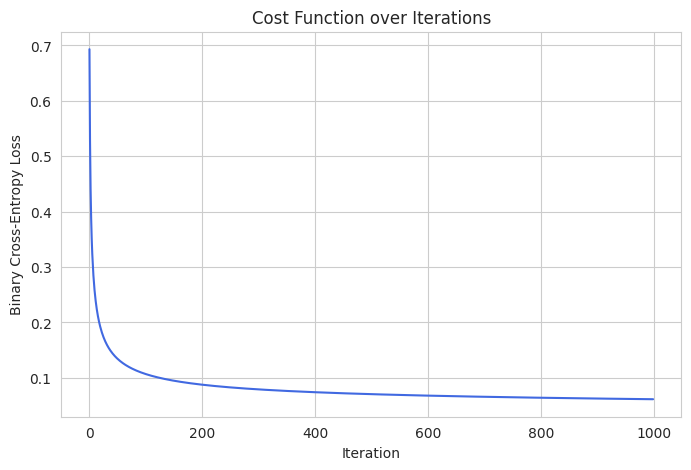

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(model.cost_history, color='royalblue')
plt.title("Cost Function over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.show()

## 8. Model Evaluation

We'll look at:
- **Confusion Matrix** — breakdown of correct/incorrect predictions
- **Precision, Recall, F1-score**
- **ROC Curve and AUC**

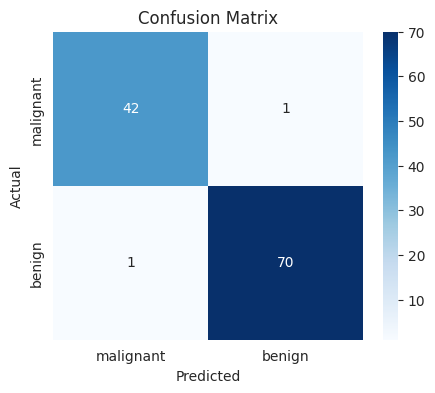

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        43
      benign       0.99      0.99      0.99        71

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred, target_names=data.target_names))

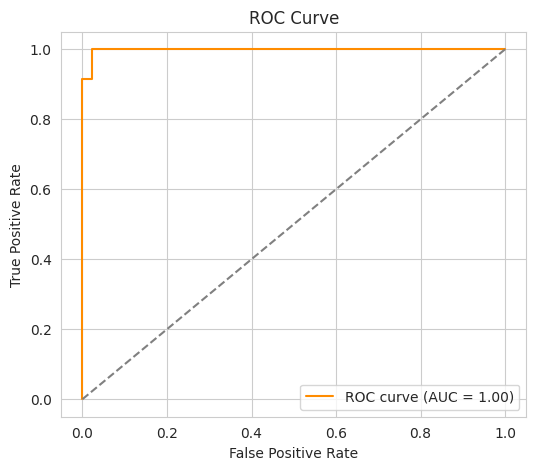

In [8]:
y_proba = model.predict_proba(X_test_scaled)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## 9. Comparing with Scikit-learn's Logistic Regression

Let's verify our from-scratch implementation against the industry-standard library.

In [9]:
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression()
sk_model.fit(X_train_scaled, y_train)
sk_pred = sk_model.predict(X_test_scaled)

print("Accuracy (Scratch Model):   ", accuracy_score(y_test, y_pred))
print("Accuracy (Scikit-learn):    ", accuracy_score(y_test, sk_pred))

Accuracy (Scratch Model):    0.9824561403508771
Accuracy (Scikit-learn):     0.9736842105263158


## 10. Visualizing the Decision Boundary (2D Example)

To visualize a decision boundary, we reduce the problem to 2 features using a synthetic dataset.

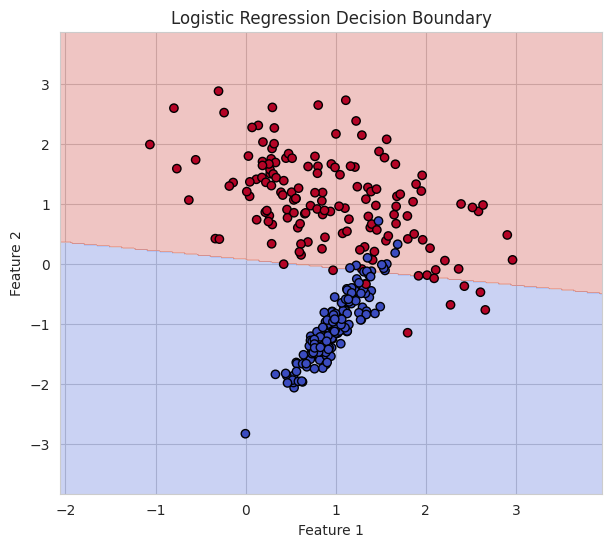

In [10]:
X2, y2 = make_classification(
    n_samples=300, n_features=2, n_redundant=0,
    n_informative=2, n_clusters_per_class=1, random_state=42
)

model2d = LogisticRegressionScratch(learning_rate=0.1, n_iterations=1000)
model2d.fit(X2, y2)

x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                      np.arange(y_min, y_max, 0.02))

Z = model2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap='coolwarm', edgecolors='k')
plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## 📌 Key Takeaways

- Logistic Regression predicts **probabilities** using the sigmoid function, then applies a threshold (usually 0.5) to classify.
- It is trained by minimizing **Binary Cross-Entropy Loss** using **Gradient Descent**.
- Feature scaling matters — it speeds up convergence significantly.
- Our from-scratch implementation achieves performance very close to scikit-learn's built-in model, confirming the math is correctly implemented.
- Logistic Regression works best when classes are (roughly) linearly separable.
